# 36-bus graph comparison: IL vs IL + RL

Tables II and III of the paper.

Does the graph representation of the observation matter on IEEE-36 (`l2rpn_wcci_2020`), and does the
difference persist after RL fine-tuning? The 12 representations of the graph comparison, all with the
Complete node features: 11 graphs with a GCN and per-substation readout (`model=gcn_substation_readout`),
among them `no_edges` (the nodes without any edges, structure control), and `flat` (RLlib's default MLP on
the flattened features).

Per representation and training seed (0–4):

- **Junior (IL)**: the best HPO trial of `graph36_<obs>`, retrained with the seed.
- **Senior (IL + RL)**: PPO (`senior_warmup`, 200k agent steps) from that Junior's weights. Each Senior
  ran on CPU and GPU in parallel; the first to finish was kept (`eval/senior_s<seed>/trained_on.txt`).
  RL setup: every rollout worker plays the train chronics in its own random order, every
  evaluation plays all 144 val chronics, and the exported checkpoint is the one with the highest val
  survival (`eval/senior_s<seed>/checkpoint_selection.json`). Senior val survival is therefore slightly
  optimistic; **test is the unbiased split** (Table II).

Both are rolled out greedily (argmax) on `l2rpn_wcci_2020_val` and `l2rpn_wcci_2020_test` (144 chronics
each, the same chronics and env seeds for every agent). Run: `slurm/unicluster/graph_comparison_36bus_senior.sh`.

**Metrics.** Per seed: *survived steps* = mean over chronics of steps survived / chronic length;
*survived episodes* = share of chronics survived to the end. Tables: mean ± SD over seeds (sample SD).
Only seeds with all 144 chronics of a split count; missing or incomplete seeds are listed below.

**Data.** `EXPERIMENT` selects `results/senior/<EXPERIMENT>/` (the paper's rollout tables are included in the repository):
```
<obs>/junior_s<seed>/rollout/episodes_{valenv,testenv}_*.csv       Junior rollouts (one file per rollout task/process)
<obs>/eval/senior_s<seed>/rollout/episodes_{valenv,testenv}_*.csv  Senior rollouts
```


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))

from analysis.episodes import survival_over_seeds, survival_per_seed

# ── Experiment ──
EXPERIMENT = "2026_11_11_IEEE36_graph_comparison_senior_v2"  # results/senior/<EXPERIMENT>/
OBS_SPACES = ["no_edges", "substation", "complete", "elements", "heterogeneous", "lodf", "ptdf", "zbus",
              "elements_lodf", "substation_ptdf", "substation_zbus", "flat"]
SEEDS = range(5)
SPLITS = {"val": "valenv", "test": "testenv"}  # Grid2Op env -> tag of the episode files
N_CHRONICS = 144  # chronics per env split
STAGES = {"IL": "junior_s{seed}", "IL + RL": "eval/senior_s{seed}"}  # stage (Junior, Senior) -> run folder

EXP_DIR = ROOT / "results/senior" / EXPERIMENT
assert EXP_DIR.exists(), f"{EXP_DIR} not found"

## Rollouts per seed

Loads every seed's episode tables (the rollout tasks of a split appended) and keeps the complete seeds.
Missing or incomplete seeds are listed and left out of all tables below.

In [2]:
def rollout_folders(obs: str, stage: str) -> dict[int, Path]:
    """seed -> rollout folder of one representation and stage."""
    return {seed: EXP_DIR / obs / STAGES[stage].format(seed=seed) / "rollout" for seed in SEEDS}


def incomplete_seeds(per_seed: pd.DataFrame) -> dict[int, int]:
    """seed -> chronics found, for every seed of SEEDS without all N_CHRONICS chronics."""
    found = per_seed["chronics"].reindex(SEEDS, fill_value=0)
    return {seed: int(n) for seed, n in found.items() if n != N_CHRONICS}


PER_SEED = {}  # (stage, split, obs) -> one row per complete seed (index seed, SurvivalMetrics columns)
missing = []
for stage in STAGES:
    for split, tag in SPLITS.items():
        for obs in OBS_SPACES:
            per_seed = survival_per_seed(rollout_folders(obs, stage), tag)
            gaps = incomplete_seeds(per_seed)
            missing += [f"{stage}, {split}, {obs} s{seed}: {n}/{N_CHRONICS} chronics" for seed, n in gaps.items()]
            PER_SEED[(stage, split, obs)] = per_seed.drop(index=[s for s in gaps if s in per_seed.index])

print("Missing or incomplete, left out:" if missing else "All seeds complete.")
for line in missing:
    print("  " + line)

All seeds complete.


## Survival per env split

One table per split. Rows: representations; columns: IL (Junior) and IL + RL (Senior).
Mean ± SD over the complete seeds, in %.

In [3]:
def pm(mean: float, sd: float) -> str:
    """'mean ± SD' with one decimal; SD left out for one seed (NaN), '–' without seeds."""
    if np.isnan(mean):
        return "–"
    return f"{mean:.1f}" if np.isnan(sd) else f"{mean:.1f} ± {sd:.1f}"


def stage_columns(per_seed: pd.DataFrame, stage: str) -> dict[tuple[str, str], str | int]:
    """(stage, column) -> value: step and episode survival (mean ± SD over seeds) and the seed count.

    Args:
        per_seed: One row per seed with `mean_survival_pct` and `full_survival_pct`.
        stage: Key of STAGES, the top level of the column names.
    """
    s = survival_over_seeds(per_seed)
    return {(stage, "Survived steps (%)"): pm(s.steps_pct, s.steps_sd),
            (stage, "Survived episodes (%)"): pm(s.episodes_pct, s.episodes_sd),
            (stage, "Seeds"): s.seeds}


def split_table(split: str) -> pd.DataFrame:
    """One row per representation, IL and IL + RL survival side by side (two-level columns: stage, metric)."""
    rows = {obs: {k: v for stage in STAGES for k, v in stage_columns(PER_SEED[(stage, split, obs)], stage).items()}
            for obs in OBS_SPACES}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.columns = pd.MultiIndex.from_tuples(table.columns)
    return table.rename_axis("Representation")


def show(table: pd.DataFrame, title: str) -> None:
    """Display a table and print it as markdown (columns flattened to 'stage: metric') for copying."""
    print(title)
    display(table)
    flat = table.set_axis([f"{stage}: {metric}" for stage, metric in table.columns], axis=1)
    print(flat.to_markdown(), "\n")


for split in SPLITS:
    show(split_table(split), f"{split} env")

val env


IL                              \
                Survived steps (%) Survived episodes (%) Seeds   
Representation                                                   
no_edges                32.0 ± 6.0            14.3 ± 4.7     5   
substation              34.7 ± 3.5            16.4 ± 3.0     5   
complete                38.0 ± 2.4            19.0 ± 3.3     5   
elements                34.9 ± 3.2            17.4 ± 1.3     5   
heterogeneous           41.0 ± 4.2            21.9 ± 3.3     5   
lodf                    44.9 ± 4.5            26.1 ± 5.4     5   
ptdf                    38.8 ± 3.3            20.7 ± 4.9     5   
zbus                    39.9 ± 3.6            20.6 ± 3.5     5   
elements_lodf           38.7 ± 4.9            21.2 ± 3.3     5   
substation_ptdf         44.2 ± 5.2            24.9 ± 5.7     5   
substation_zbus         40.4 ± 4.4            21.1 ± 3.3     5   
flat                    46.2 ± 2.1            29.6 ± 2.8     5   

                           IL + RL                              
                Survived steps (%) Survived episodes (%) Seeds  
Representation                                                  
no_edges                76.3 ± 2.5            60.6 ± 3.1     5  
substation              79.1 ± 3.8            65.0 ± 3.3     5  
complete                77.1 ± 1.6            60.1 ± 2.8     5  
elements                75.5 ± 1.4            60.7 ± 2.2     5  
heterogeneous           69.9 ± 2.0            51.9 ± 4.1     5  
lodf                    74.2 ± 1.9            57.1 ± 1.1     5  
ptdf                    71.0 ± 8.3            54.7 ± 9.7     5  
zbus                    73.6 ± 6.8            58.8 ± 6.3     5  
elements_lodf           72.7 ± 4.0            54.4 ± 6.0     5  
substation_ptdf         75.5 ± 3.3            60.3 ± 2.8     5  
substation_zbus         74.8 ± 1.6            60.3 ± 2.2     5  
flat                    68.1 ± 4.1            49.7 ± 4.1     5

| Representation   | IL: Survived steps (%)   | IL: Survived episodes (%)   |   IL: Seeds | IL + RL: Survived steps (%)   | IL + RL: Survived episodes (%)   |   IL + RL: Seeds |
|:-----------------|:-------------------------|:----------------------------|------------:|:------------------------------|:---------------------------------|-----------------:|
| no_edges         | 32.0 ± 6.0               | 14.3 ± 4.7                  |           5 | 76.3 ± 2.5                    | 60.6 ± 3.1                       |                5 |
| substation       | 34.7 ± 3.5               | 16.4 ± 3.0                  |           5 | 79.1 ± 3.8                    | 65.0 ± 3.3                       |                5 |
| complete         | 38.0 ± 2.4               | 19.0 ± 3.3                  |           5 | 77.1 ± 1.6                    | 60.1 ± 2.8                       |                5 |
| elements         | 34.9 ± 3.2               | 17.4 ± 1.3                  |           5 | 75.5 ± 1.4        

IL                              \
                Survived steps (%) Survived episodes (%) Seeds   
Representation                                                   
no_edges                32.5 ± 6.7            12.8 ± 5.7     5   
substation              33.7 ± 5.2            13.6 ± 4.5     5   
complete                38.9 ± 3.2            16.5 ± 2.4     5   
elements                34.5 ± 3.4            14.2 ± 3.7     5   
heterogeneous           38.4 ± 5.3            16.9 ± 3.9     5   
lodf                    42.5 ± 3.1            22.6 ± 3.5     5   
ptdf                    39.5 ± 1.4            17.8 ± 2.1     5   
zbus                    38.4 ± 1.7            14.7 ± 1.8     5   
elements_lodf           36.9 ± 6.3            16.7 ± 6.0     5   
substation_ptdf         42.6 ± 4.6            21.5 ± 4.5     5   
substation_zbus         39.7 ± 2.5            18.2 ± 1.7     5   
flat                    45.0 ± 3.8            23.6 ± 4.0     5   

                           IL + RL                              
                Survived steps (%) Survived episodes (%) Seeds  
Representation                                                  
no_edges                70.7 ± 2.9            49.9 ± 3.8     5  
substation              76.0 ± 1.8            58.5 ± 3.1     5  
complete                74.0 ± 2.1            53.1 ± 3.9     5  
elements                74.1 ± 4.8            54.6 ± 5.8     5  
heterogeneous           65.8 ± 3.9            43.2 ± 4.5     5  
lodf                    70.0 ± 2.5            49.4 ± 2.0     5  
ptdf                    69.1 ± 7.3            50.1 ± 6.1     5  
zbus                    69.4 ± 5.7            50.4 ± 3.3     5  
elements_lodf           69.3 ± 5.5            48.1 ± 6.4     5  
substation_ptdf         74.5 ± 4.7            55.8 ± 6.1     5  
substation_zbus         71.1 ± 3.1            51.1 ± 3.7     5  
flat                    64.8 ± 7.9            43.6 ± 7.8     5

| Representation   | IL: Survived steps (%)   | IL: Survived episodes (%)   |   IL: Seeds | IL + RL: Survived steps (%)   | IL + RL: Survived episodes (%)   |   IL + RL: Seeds |
|:-----------------|:-------------------------|:----------------------------|------------:|:------------------------------|:---------------------------------|-----------------:|
| no_edges         | 32.5 ± 6.7               | 12.8 ± 5.7                  |           5 | 70.7 ± 2.9                    | 49.9 ± 3.8                       |                5 |
| substation       | 33.7 ± 5.2               | 13.6 ± 4.5                  |           5 | 76.0 ± 1.8                    | 58.5 ± 3.1                       |                5 |
| complete         | 38.9 ± 3.2               | 16.5 ± 2.4                  |           5 | 74.0 ± 2.1                    | 53.1 ± 3.9                       |                5 |
| elements         | 34.5 ± 3.4               | 14.2 ± 3.7                  |           5 | 74.1 ± 4.8        

## 14 bus vs 36 bus: do the rankings agree?

The same representations on the 14 bus grid (`2026_10_28_compare_graph_obs_spaces_IEEE14`): PPO from scratch
(no IL), 5 seeds, latest checkpoint, 50 test episodes per seed (`<obs>/CustomPPO*/analysis/survival/`). `flat`
here is `flat_rllib_mlp` (RLlib's default MLP, as on 36 bus). Same metrics as above. A seed counts only with all
50 episodes.

14 bus, RL, test


,Survived steps (%),Survived episodes (%),Seeds
Representation,,,
no_edges,99.1 ± 0.9,98.4 ± 1.7,5
substation,99.2 ± 1.0,98.8 ± 1.8,5
complete,98.3 ± 1.0,96.8 ± 1.8,5
elements,98.7 ± 0.8,97.6 ± 1.7,5
heterogeneous,97.7 ± 1.2,96.0 ± 2.0,5
lodf,98.1 ± 2.1,97.2 ± 3.0,5
ptdf,98.2 ± 1.2,97.2 ± 1.8,5
zbus,98.8 ± 1.1,97.6 ± 2.2,5
elements_lodf,97.6 ± 1.3,96.0 ± 2.4,5


| Representation   | Survived steps (%)   | Survived episodes (%)   |   Seeds |
|:-----------------|:---------------------|:------------------------|--------:|
| no_edges         | 99.1 ± 0.9           | 98.4 ± 1.7              |       5 |
| substation       | 99.2 ± 1.0           | 98.8 ± 1.8              |       5 |
| complete         | 98.3 ± 1.0           | 96.8 ± 1.8              |       5 |
| elements         | 98.7 ± 0.8           | 97.6 ± 1.7              |       5 |
| heterogeneous    | 97.7 ± 1.2           | 96.0 ± 2.0              |       5 |
| lodf             | 98.1 ± 2.1           | 97.2 ± 3.0              |       5 |
| ptdf             | 98.2 ± 1.2           | 97.2 ± 1.8              |       5 |
| zbus             | 98.8 ± 1.1           | 97.6 ± 2.2              |       5 |
| elements_lodf    | 97.6 ± 1.3           | 96.0 ± 2.4              |       5 |
| substation_ptdf  | 98.4 ± 0.3           | 97.2 ± 1.1              |       5 |
| substation_zbus  | 97.5 ± 1.6         

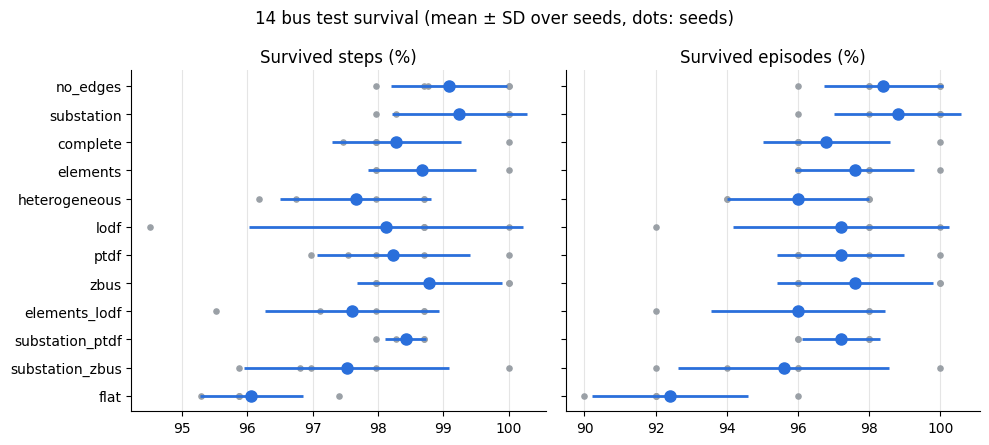

In [4]:
import matplotlib.pyplot as plt

EXP14_DIR = ROOT / "results/2026_10_28_compare_graph_obs_spaces_IEEE14"
FOLDERS_14 = {obs: obs for obs in OBS_SPACES} | {"flat": "flat_rllib_mlp"}  # 36 bus name -> 14 bus folder
N_EPISODES_14 = 50


def survival_per_seed_14(obs: str) -> pd.DataFrame:
    """One row per 14 bus trial (index seed = trial in folder order): episodes, step and episode survival in %."""
    rows = {}
    for seed, trial in enumerate(sorted((EXP14_DIR / FOLDERS_14[obs]).glob("CustomPPO*/"))):
        base = trial / "analysis" / "survival"
        steps, max_steps = np.load(base / "survived_steps.npy"), np.load(base / "max_steps.npy")
        rows[seed] = {"chronics": len(steps), "mean_survival_pct": 100 * np.mean(steps / max_steps),
                      "full_survival_pct": 100 * np.mean(steps >= max_steps)}
    return pd.DataFrame.from_dict(rows, orient="index", columns=["chronics", "mean_survival_pct", "full_survival_pct"])


PER_SEED_14 = {}  # obs -> one row per complete seed
for obs in OBS_SPACES:
    per_seed = survival_per_seed_14(obs)
    incomplete = per_seed["chronics"] != N_EPISODES_14
    for seed, n in per_seed.loc[incomplete, "chronics"].items():
        print(f"14 bus {obs} s{seed}: {n}/{N_EPISODES_14} episodes, left out")
    PER_SEED_14[obs] = per_seed[~incomplete]

rows = {}
for obs, per_seed in PER_SEED_14.items():
    s = survival_over_seeds(per_seed)
    rows[obs] = {"Survived steps (%)": pm(s.steps_pct, s.steps_sd),
                 "Survived episodes (%)": pm(s.episodes_pct, s.episodes_sd), "Seeds": s.seeds}
table14 = pd.DataFrame.from_dict(rows, orient="index").rename_axis("Representation")
print("14 bus, RL, test")
display(table14)
print(table14.to_markdown(), "\n")

# Mean (marker) ± SD over seeds (bar) and the seeds (dots); axes zoomed, since all are near full survival.
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
y = np.arange(len(OBS_SPACES))
for ax, (column, title) in zip(axes, [("mean_survival_pct", "Survived steps (%)"),
                                      ("full_survival_pct", "Survived episodes (%)")]):
    values = [PER_SEED_14[obs][column] for obs in OBS_SPACES]
    for i, v in enumerate(values):
        ax.scatter(v, np.full(len(v), y[i]), s=14, color="#9aa0a6", zorder=2)
    ax.errorbar([v.mean() for v in values], y, xerr=[v.std(ddof=1) for v in values], fmt="o", ms=8,
                color="#2a6fdb", ecolor="#2a6fdb", elinewidth=2, capsize=0, zorder=3)
    ax.set_title(title)
    ax.grid(axis="x", color="#e5e5e5")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_yticks(y, OBS_SPACES)
axes[0].invert_yaxis()
fig.suptitle("14 bus test survival (mean ± SD over seeds, dots: seeds)")
fig.tight_layout()
plt.show()

### Rank and value agreement

Each row of the table correlates two survival results over the 12 representations: the 14 bus result (RL from
scratch, test) with one 36 bus result (stage IL or IL + RL, split val or test). Per representation, both sides
are the mean over seeds. Spearman ρ compares the rankings of the representations (ties: average ranks),
Pearson r the survival values, separately for step and episode survival; p in brackets. With n = 12, |ρ| below
≈ 0.58 is not significant at 5 %. The 14 bus values are near the ceiling (95–100 %) with small gaps, so its
ranking is noisy.

In [5]:
from scipy.stats import pearsonr, spearmanr

METRICS = {"steps": "mean_survival_pct", "episodes": "full_survival_pct"}


def seed_means(per_seed_by_obs: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Representation -> mean over seeds of step and episode survival (columns: METRICS keys)."""
    return pd.DataFrame({name: {obs: df[col].mean() for obs, df in per_seed_by_obs.items()}
                         for name, col in METRICS.items()}).loc[OBS_SPACES]


def corr(x: pd.Series, y: pd.Series, test) -> str:
    """'coefficient (p)' of a scipy correlation test."""
    r, p = test(x, y)
    return f"{r:+.2f} (p={p:.3f})"


means14 = seed_means(PER_SEED_14)
rows = {}
for split in SPLITS:
    means36 = seed_means({obs: PER_SEED[("IL + RL", split, obs)] for obs in OBS_SPACES})
    rows[("RL, test", f"IL + RL, {split}")] = {
        "Spearman ρ, steps": corr(means14["steps"], means36["steps"], spearmanr),
        "Spearman ρ, episodes": corr(means14["episodes"], means36["episodes"], spearmanr),
        "Pearson r, steps": corr(means14["steps"], means36["steps"], pearsonr),
        "Pearson r, episodes": corr(means14["episodes"], means36["episodes"], pearsonr),
    }
agreement = pd.DataFrame.from_dict(rows, orient="index").rename_axis(["14 bus", "36 bus"]).reset_index()
print("Correlation over the 12 representations: 14 bus result vs 36 bus result (per-representation means over seeds)")
display(agreement.style.hide(axis="index"))
print(agreement.to_markdown(index=False))

Correlation over the 12 representations: 14 bus result vs 36 bus result (per-representation means over seeds)


14 bus,36 bus,"Spearman ρ, steps","Spearman ρ, episodes","Pearson r, steps","Pearson r, episodes"
"RL, test","IL + RL, val",+0.71 (p=0.009),+0.72 (p=0.008),+0.79 (p=0.002),+0.77 (p=0.003)
"RL, test","IL + RL, test",+0.63 (p=0.028),+0.55 (p=0.065),+0.72 (p=0.009),+0.69 (p=0.012)


| 14 bus   | 36 bus        | Spearman ρ, steps   | Spearman ρ, episodes   | Pearson r, steps   | Pearson r, episodes   |
|:---------|:--------------|:--------------------|:-----------------------|:-------------------|:----------------------|
| RL, test | IL + RL, val  | +0.71 (p=0.009)     | +0.72 (p=0.008)        | +0.79 (p=0.002)    | +0.77 (p=0.003)       |
| RL, test | IL + RL, test | +0.63 (p=0.028)     | +0.55 (p=0.065)        | +0.72 (p=0.009)    | +0.69 (p=0.012)       |
